In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mpltransforms
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap # Import for custom colors

import seaborn as sns
import os
import datetime
import pickle
import itertools

from scipy.signal import find_peaks
from sklearn.mixture import GaussianMixture
from astropy.stats.circstats import circvar, circmean
from astropy.stats import kuiper
from scipy.stats import pearsonr, ks_2samp
from scipy.stats import entropy

from scipy.stats import ranksums, ttest_ind, f_oneway, false_discovery_control
import statsmodels.regression as sm
from statsmodels.multivariate.multivariate_ols import MultivariateLS
from statannotations.Annotator import Annotator

from pycircstat2.hypothesis import wheeler_watson_test, watson_u2_test
from pycircstat2 import Circular

from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve
from sklearn.mixture import GaussianMixture

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.dataproc import utils, ccutils
from src.model import linearreg, mlmodel
from src.visualize import cycleviz

### Supporting functions

In [5]:
setpairedcolorlist = sns.color_palette('Paired')
setpairedred = setpairedcolorlist[5]
setpairedgreen = setpairedcolorlist[3]
setpairedblue = setpairedcolorlist[1]
setpairedlightblue = setpairedcolorlist[0]


### Stimulation

In [6]:
save_flag = False

In [7]:
fname_format = 'data/RNSdata/NPEhistograms/%s_Histogram_Hourly.csv'
patcodes_path = 'data/RNSdata/Outcome/Hippo_outcomes_postprocessed_2025April08.csv'
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lsdf_path = 'data/processed/lscycles/plv_postproc_interval/%s.csv'  # interval or not?

outfig_dir = 'output/circpaper_figures/fig05/'

if (not os.path.exists(outfig_dir)) and (save_flag):
    os.mkdir(outfig_dir)
    print('Created a new directory.')

In [8]:
outcome_type = 'wtavg_perc_szred'

patcodesdf = pd.read_csv(patcodes_path)

patcodesdf['sz_red'] = patcodesdf[outcome_type].apply(lambda x: -x/100 if x < 0 else 0)
patcodesdf['seizure_rate'] = patcodesdf['baseline_seizure_rate'] * (1 - patcodesdf['sz_red'])
patcodesdf['log_seizure_rate'] = np.log(patcodesdf['seizure_rate'] + (np.exp(-3.5) * (patcodesdf['seizure_rate'] == 0)))
patcodesdf['log_baseline_seizure_rate'] = np.log(patcodesdf['baseline_seizure_rate'])

# patcodesdf['Responder_Type'] = patcodesdf['sz_red'].apply(lambda x: szred_to_responder(x))
# patcodesdf['Responder_Type_50'] = patcodesdf['Responder_Type'].apply(lambda x: 'NR' if x=='NR' else 'SR+IR')
# patcodesdf['Responder_Type_90'] = patcodesdf['Responder_Type'].apply(lambda x: 'SR' if x=='SR' else 'IR+NR')

patient_list = ccutils.final_patient_list()

patoutcome_cols = ['npe_code', 'sz_red', 'log_baseline_seizure_rate', 'log_seizure_rate']

lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes

In [9]:
dfdict = {}

npe0041_date_format = "%m/%d/%y %H:%M"

for patient_id in patient_list:
    fname = fname_format %(patient_id)
    if not os.path.exists(fname):
        print(f'{patient_id}: Histogram file doesnt exist.')
        continue
        
    df = pd.read_csv(fname)
    
    if patient_id == 'NPE0041': # update the formatting of time bins for this patient
        df['Region start time'] = df['Region start time'].apply(lambda x: datetime.datetime.strptime(x, npe0041_date_format).isoformat(sep=' '))
    
    df['Local_hour'] = df['Region start time'].apply(lambda x: datetime.datetime.fromisoformat(x).hour)
    df['npe_code'] = patient_id
    # df['Responder_Type'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].Responder_Type.item()
    df['sz_red'] = patcodesdf.loc[patcodesdf['npe_code']==patient_id].sz_red.item()
    df['RX_norm'] = (df['Episode starts with RX'] - df['Episode starts with RX'].mean()) / df['Episode starts with RX'].std()
    max_hour = df.groupby(by='Local_hour')['Episode starts with RX'].mean().idxmax()
    df['Maxalgn_hour'] = (df['Local_hour'] - max_hour)  % 24
    df['Maxalgn_mid_hour'] = ( df['Maxalgn_hour'] - 12 ) % 24
    
    # time from implantation
    implantdt = datetime.datetime.fromisoformat(patcodesdf.loc[patcodesdf['npe_code']==patient_id]['implant_date'].item())
    utils.tfromstart_days(df, datecol='Region start time', start_date=implantdt)
    ccutils.round_half_year_days(df)
    
    dfdict[patient_id] = df.copy()

In [10]:
MIN_LS_NSAMP = 120   # 120 MAGIC for interval LS models, 0 otherwise
lsdata_cols = ['amp_unnorm_%s', 'amp_norm_%s', 'peakhour_%s', 'fitpower_%s', 'pvalue_%s']


# read the cycle charateristics csv file and store in a dictionary
lsdf_dict = {}

for patient_id in patient_list:
    
    if not os.path.exists(lsdf_path % (patient_id)):
        print(f'{patient_id}: No LS file found. Removing from patient list.')
        continue
    
    lsdf = pd.read_csv(lsdf_path % (patient_id))  # read Ls file
    
    pat_days_list = [int(item.split('_')[-1]) for item in lsdf.columns if ('nsamp' in item)]
    
    # blank out times with samples less than some threshold
    for daynum in pat_days_list:
        if lsdf[f'nsamp_{daynum}'].iloc[0] < MIN_LS_NSAMP:
            pat_lsdata_cols = [item%(daynum) for item in lsdata_cols]
            lsdf[pat_lsdata_cols] = np.NaN
    
    # store the dataframe
    lsdf_dict[patient_id] = lsdf.copy()
    

## Key dataframes

In [11]:
normtype = 'zeroone'  # 'zeroone', 'maxnorm'
lgmscdict = ccutils.mean_stimcounts(dfdict, patient_list, groupby=['dur_halfyr', 'Local_hour'], 
                                    normtype=normtype)

In [12]:
interval_start = 7  # MAGIC; change based on normtype. zeroone=7, maxnorm=5
interval_end = 11

lgaucdf = ccutils.longi_interval_aucdf(lgmscdict, patient_list, interval_start, interval_end, verbose=True)

Dropped entries because stim AUC=0: # 9


In [13]:
feature_list = lsdf_dict[patient_list[0]]['feature'].to_list()
band_list = ['theta', 'alpha', 'beta', 'gamma']
edge_type_list = ['local']  # local FC, long-range FC, both FCs

subfeatdict = ccutils.get_subfeatdict(feature_list, band_list, edge_type_list)

print('Verify the number of features of each type in the dict:')
print([len(subfeatdict[keyval1][keyval2]) for keyval1 in subfeatdict.keys() 
       for keyval2 in subfeatdict[keyval1].keys()])

Verify the number of features of each type in the dict:
[2, 2, 2, 2, 8]


In [14]:
band_list = ['alpha']
edge_type_list = ['local']

## compute the LS amplitude across different feature types for each patient
lgfeatdf = ccutils.create_lgfcccfeat_dataframe(lsdf_dict, patient_list, band_list, edge_type_list, subfeatdict)

# hour at which FC-CC are max in prob for both hemispheres
lgpkhourdf = ccutils.longi_mean_cycle_peakhour(lsdf_dict, patient_list, band_list, 
                                               edge_type_list, subfeatdict)

lgfeatdf = lgfeatdf.merge(lgpkhourdf, on=['npecode', 'band', 'days_from_implant'])

# pair with previous 6-month window observations
lgfeatdf = ccutils.align_curr_previous_fccc(lgfeatdf, pivot_band_into_column=False)

# combine stimulation feature with FC-CC features
lgdf = lgaucdf.merge(lgfeatdf, how='left', left_on=['npecode', 'dur_day'],
                     right_on=['npecode', 'days_from_implant'])
lgdf.dropna(axis=0, inplace=True)  # remove rows with nans

In [15]:
lgaucdf.shape[0], lgfeatdf.shape[0], lgdf.shape[0]

(359, 233, 172)

In [16]:
lgaucdf.shape[0], lgfeatdf.shape[0], lgdf.shape[0]

(359, 233, 172)

In [17]:
# combine left and right (cycle 1 and 2) into a single column
fsdf = ccutils.melt_left_right_into_single_column(lgdf)

In [18]:
fsdf.shape

(344, 20)

In [19]:
fsdf.shape

(344, 20)

In [20]:
xylabeldict = {'ffprev_gap': r'|$\Delta$ Circadian peak| (hour)',
               'ffprev_sgngap': r'$\Delta$ Circadian peak (hour)'}

## effectsize ytick labels
mcoef_ytldict = {'amp_prev': '$A^{c}_{t-6mo}$',
                 # 'amp_prev_deltasign': r'$\pm$ FC-CC amp$_{t-1}$',
                 'sin_fccc_prev': r'sin($\phi^{c}_{t-6mo}$)', 
                 'cos_fccc_prev': 'cos($\phi^{c}_{t-6mo}$)', 
                 'auc_interval': f'SPA({interval_start}AM-{interval_end}AM)',
                 'auc_converse': f'SPA({interval_end}AM-{interval_start}AM)',
                 'sin_stim': r'sin($\phi^{s}_{t}$)', 
                 'cos_stim': r'cos($\phi^{s}_{t}$)'}

## color map for effectsize 
escolordict = {1:'tab:blue', -1:'silver'}

### 5A: Schematic for circadian peak change

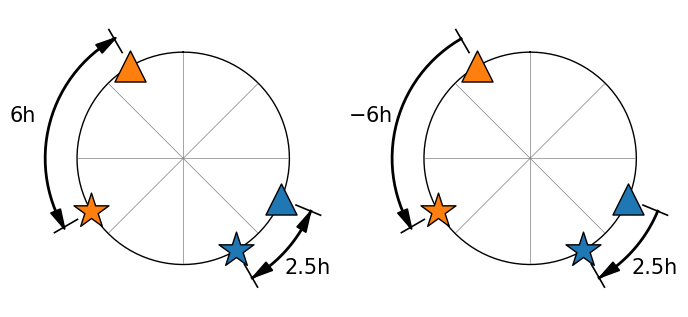

In [21]:
fccc_angles = np.pi / 12 * np.array([7.5, 10, 22, 16])
ncols = 2
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.5*ncols, 3.3*nrows),
                       subplot_kw={'projection':'polar'})
fax = ax.flatten()
plot_rmin, plot_rmax = 0, 1

# --- outside-the-circle geometry ---
line_rmin   = 1.15 * plot_rmax
line_rmax   = 1.4 * plot_rmax
arc_radius  = 1.3 * plot_rmax
outer_rlim  = 1.4  * plot_rmax
label_radius = 1.2 * arc_radius   # push text slightly outside the arc

# phase-difference labels: (pair1_label, pair2_label) per subplot
pair_labels = [('2.5h', '6h'), ('2.5h', r'$-$6h')]

circle_theta = np.linspace(0, 2*np.pi, 200)

for ii in range(ncols):
    if ii == 0:
        arrowend = 'both'
    else:
        arrowend = 'end'

    # --- explicit circle at r = plot_rmax ---
    fax[ii].plot(circle_theta, np.full_like(circle_theta, plot_rmax),
                 color='k', linewidth=1.0, zorder=0)

    ### FC-CC - pair 1
    fax[ii].plot([fccc_angles[0], fccc_angles[0]], [line_rmin, line_rmax],
                 color='k', linestyle='-', linewidth=1.2,
                 clip_on=False, zorder=1)
    fax[ii].plot([fccc_angles[1], fccc_angles[1]], [line_rmin, line_rmax],
                 color='k', linestyle='-', linewidth=1.2,
                 clip_on=False, zorder=1)

    fax[ii].scatter(fccc_angles[0], plot_rmax, color='tab:blue', marker='^', s=500, edgecolor='k', clip_on=False, zorder=3)
    fax[ii].scatter(fccc_angles[1], plot_rmax, color='tab:blue', marker='*', s=700, edgecolor='k', clip_on=False, zorder=3)
    cycleviz.arrow_arc_long(ax=fax[ii], start_angle=fccc_angles[0], end_angle=fccc_angles[1],
                            arrow_radius=arc_radius, color='k', arrowend=arrowend)
    mid_angle1 = (fccc_angles[0] + fccc_angles[1]) / 2
    fax[ii].text(mid_angle1, label_radius, pair_labels[ii][0],
                 color='k', ha='center', va='center', fontsize=15,
                 clip_on=False, zorder=4)

    ### FC-CC - pair 2
    fax[ii].plot([fccc_angles[2], fccc_angles[2]], [line_rmin, line_rmax],
                 color='k', linestyle='-', linewidth=1.2,
                 clip_on=False, zorder=1)
    fax[ii].plot([fccc_angles[3], fccc_angles[3]], [line_rmin, line_rmax],
                 color='k', linestyle='-', linewidth=1.2,
                 clip_on=False, zorder=1)

    fax[ii].scatter(fccc_angles[2], plot_rmax, color='tab:orange', marker='^', s=500, edgecolor='k', clip_on=False, zorder=3)
    fax[ii].scatter(fccc_angles[3], plot_rmax, color='tab:orange', marker='*', s=700, edgecolor='k', clip_on=False, zorder=3)
    cycleviz.arrow_arc_long(ax=fax[ii], start_angle=fccc_angles[2], end_angle=fccc_angles[3],
                            arrow_radius=arc_radius, color='k', arrowend=arrowend)
    mid_angle2 = (fccc_angles[2] + fccc_angles[3]) / 2
    fax[ii].text(mid_angle2, label_radius, pair_labels[ii][1],
                 color='k', ha='center', va='center', fontsize=15,
                 clip_on=False, zorder=4)

    # aesthetics
    fax[ii].set_rlim([plot_rmin, outer_rlim])

    fax[ii].set_theta_zero_location("N")
    fax[ii].set_theta_direction(-1)
    fax[ii].set_xticks(ticks=[0, np.pi/4, 2*np.pi/4, 3*np.pi/4,
                         np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4],
                  labels=['', '', '', '', '', '', '', ''], fontsize=13)
    [fax[ii].plot([ag, ag], [plot_rmin, 0.99*plot_rmax], color='gray', linewidth=0.5) 
     for ag in [0, np.pi/4, 2*np.pi/4, 3*np.pi/4, np.pi, 5*np.pi/4, 6*np.pi/4, 7*np.pi/4]]
    fax[ii].set_yticks([])
    fax[ii].set_title('', fontsize=14)

    # hide the actual polar axes spine (which now sits at outer_rlim)
    fax[ii].spines['polar'].set_visible(False)
    fax[ii].grid(False)

fig.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'schematic_polars.pdf', dpi=300)
    
plt.show()

### 5B. Predicted signed change in circadian peak

In [22]:
### recursive feature elimination
regfeat_cols = ['amp_prev', 'sin_fccc_prev', 'cos_fccc_prev',
                'auc_interval', 'auc_converse', 'sin_stim', 'cos_stim']

yvar = 'ffprev_sgngap'

cvregdf = fsdf.copy()

final_regfeats = linearreg.recursive_feature_elimination(regdf=cvregdf, 
                                                         full_feature_list=regfeat_cols, yvar=yvar, 
                                                         cv_folds_list=patient_list, cv_var='npecode', 
                                                         remove_outliers=True)

print('!!!!!!!! Final feature list:', final_regfeats, '!!!!!!!!!!!!!')

### cross-validation
lmpreddf, lmmoddict = linearreg.cross_validation(regdf=cvregdf, 
                                                 regfeat_cols=final_regfeats, yvar=yvar, 
                                                 cv_folds_list=patient_list, cv_var='npecode', 
                                                 remove_outliers=True)

Removed outliers. Num entries: 282.
Cross-validation complete.
Significance counts of each feature:
 amp_prev__pvalue          0
sin_fccc_prev__pvalue     0
cos_fccc_prev__pvalue     0
auc_interval__pvalue     27
auc_converse__pvalue     30
sin_stim__pvalue          0
cos_stim__pvalue         29
dtype: int64
Removed outliers. Num entries: 292.
Cross-validation complete.
Significance counts of each feature:
 auc_interval__pvalue    30
auc_converse__pvalue    30
cos_stim__pvalue        30
dtype: int64
!!!!!!!! Final feature list: ['auc_interval', 'auc_converse', 'cos_stim'] !!!!!!!!!!!!!
Removed outliers. Num entries: 292.
Cross-validation complete.


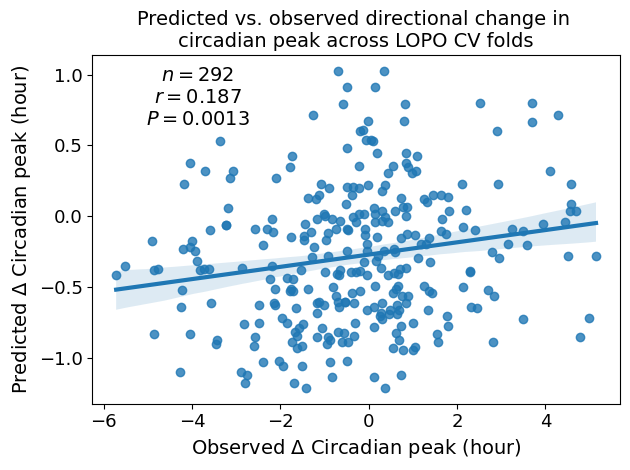

In [23]:
corrval = pearsonr(lmpreddf['gt'], lmpreddf['modpred'])

# model prediction
ax = sns.regplot(data=lmpreddf, x='gt', y='modpred', label='Model prediction', 
                 color='tab:blue', line_kws={'linewidth':3})

# annotations
ax.text(x=0.2, y=0.8, s='$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(lmpreddf.shape[0], 
                                                     corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel(f'Observed {xylabeldict[yvar]}', fontsize=14)
ax.set_ylabel(f'Predicted {xylabeldict[yvar]}', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title(f'Predicted vs. observed directional change in \ncircadian peak across LOPO CV folds', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outfig_dir + 'dirchange_scatter.pdf', dpi=300)

plt.show()

In [24]:
corrval

PearsonRResult(statistic=0.18687538561563105, pvalue=0.0013369078165006534)

## Fig 5C: Directional change model weights

In [25]:
## effectsize
lmsummary = linearreg.summarize_model_cv(lmmoddict, cv_var='npecode')
effectsize = linearreg.effect_size_across_folds(lmsummary)
effectsize = utils.include_excluded_features_in_effectsize_df(effectsize, regfeat_cols)  # effectsize of excluded variables

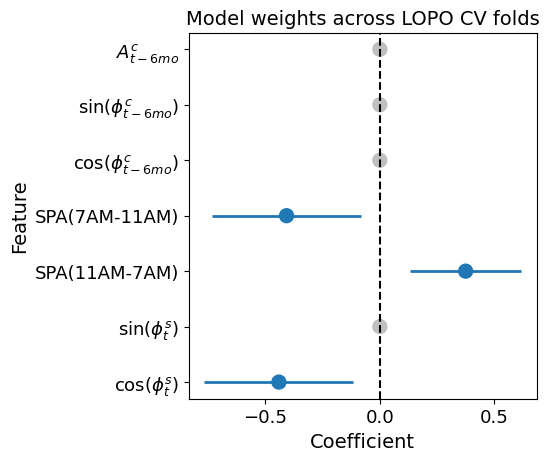

In [26]:
fig, ax = plt.subplots(1,1, figsize=(5.35, 4.5), layout='constrained')


ax.scatter(effectsize['coef'].values, effectsize['xticks'].values, s=100, 
           c=[escolordict[item] for item in effectsize['sig'].values])
ax.hlines(y=effectsize['xticks'].values, xmin=effectsize['lower'].values, xmax=effectsize['upper'].values, 
             linewidth=2, colors=[escolordict[item] for item in effectsize['sig'].values])
ax.axvline(x=0, color='black', linestyle='--')
ax.set_yticks(ticks=effectsize['xticks'].values, 
              labels=[mcoef_ytldict[item] for item in effectsize.index], fontsize=13)

ax.set_ylabel('Feature', fontsize=14)
ax.set_xlabel('Coefficient', fontsize=14)
ax.tick_params(labelsize=13)
ax.set_title('Beta weights', fontsize=14)

ax.set_title('Model weights across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outfig_dir + 'dirchange_weights.pdf', dpi=300)

plt.show()